In [2]:
# Install required packages if needed
!pip install kagglehub scikit-image tensorflow matplotlib

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import color
from skimage import io
from tensorflow.keras.preprocessing.image import img_to_array, load_img
import kagglehub
from glob import glob
import cv2
from sklearn.model_selection import train_test_split

# TensorFlow imports
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Conv2D, UpSampling2D, Conv2DTranspose, BatchNormalization, MaxPooling2D, Concatenate
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard
from tensorflow.keras.optimizers import Adam
from tensorflow import keras
from tensorflow.keras import layers
from datetime import datetime

In [4]:
# Download dataset
print("Downloading dataset...")
path = kagglehub.dataset_download("aayush9753/image-colorization-dataset")
print(f"Dataset downloaded to: {path}")

100%|██████████| 473M/473M [00:07<00:00, 67.9MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1


In [5]:
# Function to load and preprocess images
def load_img_lab(img_path, target_size=(256, 256)):
    """
    Load an image, resize it and convert to LAB color space
    Returns L and AB channels separately
    """
    # Load and resize image
    img = load_img(img_path, target_size=target_size)
    img = img_to_array(img) / 255.0  # Normalize to [0, 1]

    # Convert to LAB
    lab = color.rgb2lab(img)

    # Split into L and AB channels
    l_channel = lab[:,:,0] / 100.0  # Normalize L to [0, 1]
    ab_channels = lab[:,:,1:] / 128.0  # Normalize AB to [-1, 1]

    return l_channel, ab_channels

# Function to find all image files in the dataset
def get_image_files(dataset_path):
    """
    Get all image files from the dataset directory
    """
    image_extensions = ['*.jpg', '*.jpeg', '*.png']
    image_files = []
    for ext in image_extensions:
        image_files.extend(glob(os.path.join(dataset_path, '**', ext), recursive=True))

    print(f"Found {len(image_files)} images")
    return image_files

In [6]:
# Prepare dataset
def prepare_dataset(image_files, target_size=(256, 256), max_samples=None, test_size=0.2):
    """
    Prepare train and test datasets with L and AB channels
    """
    if max_samples and max_samples < len(image_files):
        image_files = image_files[:max_samples]

    # Initialize empty arrays
    l_channels = []
    ab_channels = []

    print("Processing images...")
    for i, img_path in enumerate(image_files):
        try:
            l, ab = load_img_lab(img_path, target_size=target_size)
            l_channels.append(l)
            ab_channels.append(ab)

            if i % 100 == 0 or i == len(image_files) - 1:
                print(f"Processed {i+1}/{len(image_files)} images")
        except Exception as e:
            print(f"Error processing {img_path}: {e}")

    # Convert to numpy arrays
    l_channels = np.array(l_channels)
    ab_channels = np.array(ab_channels)

    # Reshape L for model input (add channel dimension)
    l_channels = l_channels.reshape(l_channels.shape + (1,))

    # Split into train and test sets
    l_train, l_test, ab_train, ab_test = train_test_split(
        l_channels, ab_channels, test_size=test_size, random_state=42
    )

    print(f"Training set: {l_train.shape[0]} images")
    print(f"Testing set: {l_test.shape[0]} images")

    return l_train, l_test, ab_train, ab_test

In [7]:
# Get image files
path += "/data/train_color"
print(path)
image_files = get_image_files(path)

# View a few image paths to confirm
image_files[:5]

/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color
Found 5000 images


['/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color/image2099.jpg',
 '/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color/image2939.jpg',
 '/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color/image0286.jpg',
 '/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color/image4810.jpg',
 '/root/.cache/kagglehub/datasets/aayush9753/image-colorization-dataset/versions/1/data/train_color/image1967.jpg']

In [8]:
# Prepare dataset (limiting to 1000 images for demonstration)
# Increase max_samples for better results
max_samples = 5000  # Adjust based on your available memory and processing power
img_size = 256

l_train, l_test, ab_train, ab_test = prepare_dataset(
    image_files, target_size=(img_size, img_size), max_samples=max_samples
)

print("L train shape:", l_train.shape)
print("AB train shape:", ab_train.shape)
print("L test shape:", l_test.shape)
print("AB test shape:", ab_test.shape)

Processing images...
Processed 1/5000 images
Processed 101/5000 images
Processed 201/5000 images
Processed 301/5000 images
Processed 401/5000 images
Processed 501/5000 images
Processed 601/5000 images
Processed 701/5000 images
Processed 801/5000 images
Processed 901/5000 images
Processed 1001/5000 images
Processed 1101/5000 images
Processed 1201/5000 images
Processed 1301/5000 images
Processed 1401/5000 images
Processed 1501/5000 images
Processed 1601/5000 images
Processed 1701/5000 images
Processed 1801/5000 images
Processed 1901/5000 images
Processed 2001/5000 images
Processed 2101/5000 images
Processed 2201/5000 images
Processed 2301/5000 images
Processed 2401/5000 images
Processed 2501/5000 images
Processed 2601/5000 images
Processed 2701/5000 images
Processed 2801/5000 images
Processed 2901/5000 images
Processed 3001/5000 images
Processed 3101/5000 images
Processed 3201/5000 images
Processed 3301/5000 images
Processed 3401/5000 images
Processed 3501/5000 images
Processed 3601/5000

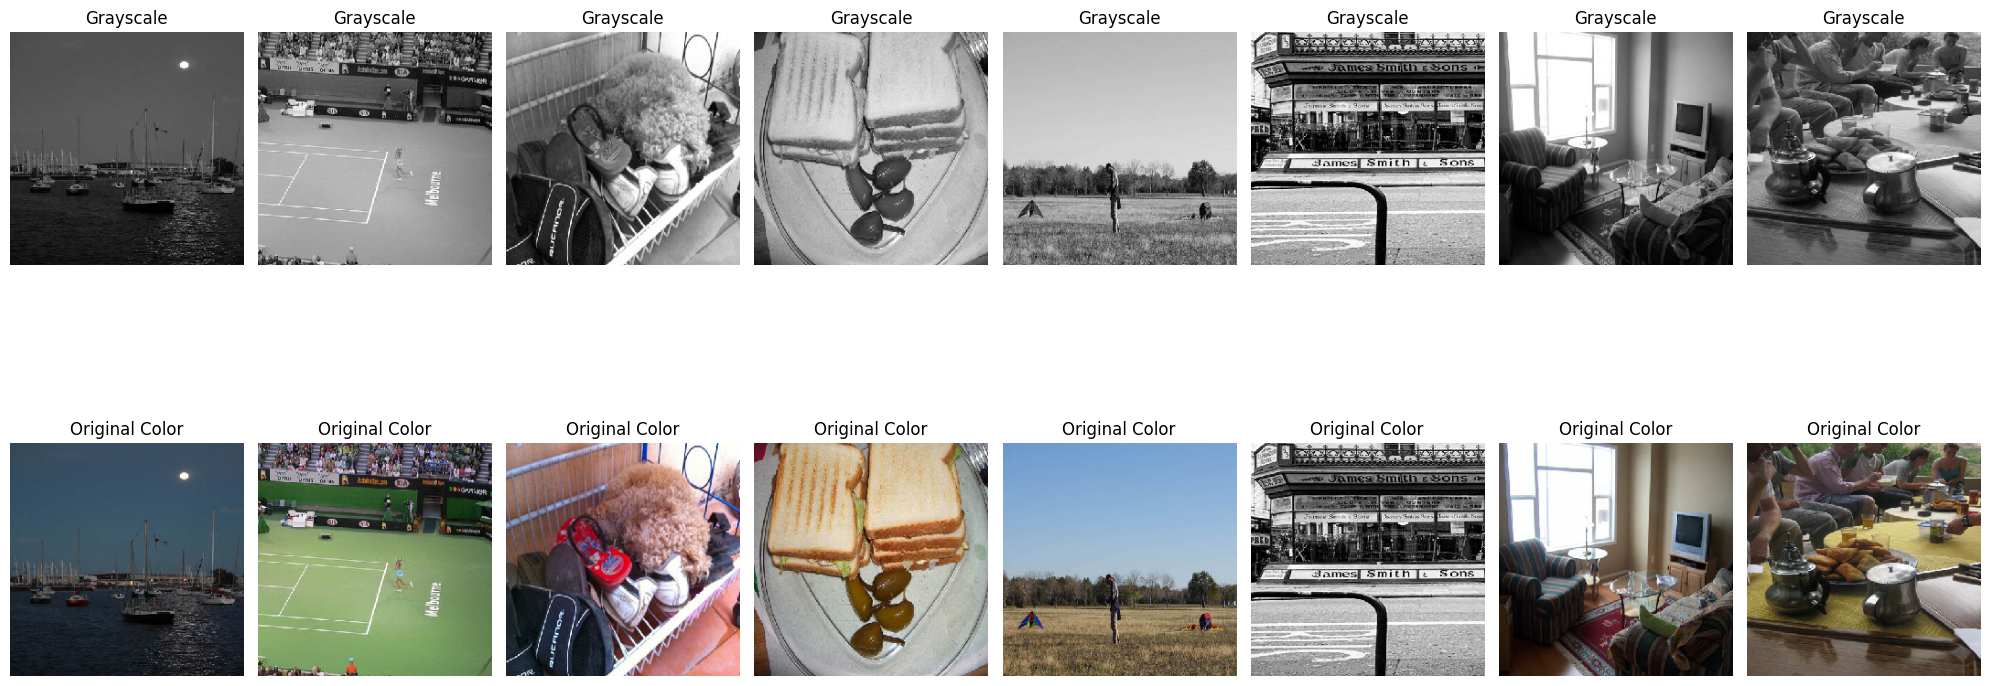

In [9]:
# Visualize original and grayscale images
def visualize_lab_images(l_channel, ab_channels, num_images=8):
    """
    Visualize grayscale and original color images
    """
    plt.figure(figsize=(20, 10))

    for i in range(min(num_images, len(l_channel))):
        # Original grayscale (L channel)
        plt.subplot(2, num_images, i + 1)
        plt.imshow(l_channel[i].squeeze(), cmap='gray')
        plt.title('Grayscale')
        plt.axis('off')

        # Reconstructed color image
        plt.subplot(2, num_images, i + num_images + 1)

        # Combine L and AB channels and convert back to RGB
        lab_img = np.zeros((l_channel[i].shape[0], l_channel[i].shape[1], 3))
        lab_img[:,:,0] = l_channel[i].squeeze() * 100
        lab_img[:,:,1:] = ab_channels[i] * 128

        # Convert LAB to RGB
        rgb_img = color.lab2rgb(lab_img)
        plt.imshow(rgb_img)
        plt.title('Original Color')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Visualize a few examples
visualize_lab_images(l_test, ab_test, num_images=8)

In [10]:
# Create the colorization CNN model
def build_colorization_model(input_shape=(256, 256, 1)):
    """
    Build a CNN model for image colorization
    Input: Grayscale image (L channel)
    Output: Color channels (AB channels)
    """
    # Input layer
    inputs = Input(shape=input_shape)

    # Encoder
    conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    conv1 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(pool1)
    conv2 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv2)
    pool2 = MaxPooling2D((2, 2))(conv2)

    conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(pool2)
    conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv3)
    pool3 = MaxPooling2D((2, 2))(conv3)

    # Middle
    conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(pool3)
    conv4 = Conv2D(512, (3, 3), activation='relu', padding='same')(conv4)

    # Decoder
    up5 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv4)
    concat5 = Concatenate()([up5, conv3])
    conv5 = Conv2D(256, (3, 3), activation='relu', padding='same')(concat5)
    conv5 = Conv2D(256, (3, 3), activation='relu', padding='same')(conv5)

    up6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv5)
    concat6 = Concatenate()([up6, conv2])
    conv6 = Conv2D(128, (3, 3), activation='relu', padding='same')(concat6)
    conv6 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv6)

    up7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv6)
    concat7 = Concatenate()([up7, conv1])
    conv7 = Conv2D(64, (3, 3), activation='relu', padding='same')(concat7)
    conv7 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv7)

    # Output layer - 2 channels for a and b
    output = Conv2D(2, (1, 1), activation='tanh')(conv7)

    model = Model(inputs=inputs, outputs=output)
    return model

# Create the model
model = build_colorization_model(input_shape=(img_size, img_size, 1))

# Display model summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 1)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 256, 256, 64)   │            640 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 256, 256, 64)   │         36,928 │ conv2d[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 128, 128, 64)   │              0 │ conv2d_1[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ conv2d_2[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 64, 64, 128)    │              0 │ conv2d_3[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 64, 64, 256)    │        295,168 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 64, 64, 256)    │        590,080 │ conv2d_4[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_2           │ (None, 32, 32, 256)    │              0 │ conv2d_5[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_6 (Conv2D)         │ (None, 32, 32, 512)    │      1,180,160 │ max_pooling2d_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_7 (Conv2D)         │ (None, 32, 32, 512)    │      2,359,808 │ conv2d_6[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose          │ (None, 64, 64, 256)    │        524,544 │ conv2d_7[0][0]         │
│ (Conv2DTranspose)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 64, 64, 512)    │              0 │ conv2d_transpose[0][0… │
│                           │                        │                │ conv2d_5[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_8 (Conv2D)         │ (None, 64, 64, 256)    │      1,179,904 │ concatenate[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_9 (Conv2D)         │ (None, 64, 64, 256)    │        590,080 │ conv2d_8[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose_1        │ (None, 128, 128, 128)  │        131,200 │ conv2d_9[0][0]         │
│ (Conv2DTranspose)    

 Total params: 7,696,258 (29.36 MB)

 Trainable params: 7,696,258 (29.36 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Create output directory for models
model_dir = 'models'
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Create logs directory for TensorBoard
log_dir = os.path.join('logs', datetime.now().strftime("%Y%m%d-%H%M%S"))
if not os.path.exists(log_dir):
    os.makedirs(log_dir)

In [12]:
# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Setup callbacks
callbacks = [
    # Save best model based on validation loss
    ModelCheckpoint(
        filepath=os.path.join(model_dir, 'colorization_model_best.h5'),
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    # Save the latest model periodically
    ModelCheckpoint(
        filepath=os.path.join(model_dir, 'colorization_model_latest.h5'),
        save_freq='epoch',
        verbose=0
    ),
    # Early stopping if model stops improving
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    # Reduce learning rate when plateau is reached
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    # TensorBoard logging
    TensorBoard(log_dir=log_dir)
]

In [13]:
# Training parameters
batch_size = 8
epochs = 50  # You can adjust this based on your patience and resources

# Train model
history = model.fit(
    l_train, ab_train,
    validation_data=(l_test, ab_test),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - loss: 0.0135
Epoch 1: val_loss improved from inf to 0.01280, saving model to models/colorization_model_best.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 227s 374ms/step - loss: 0.0135 - val_loss: 0.0128 - learning_rate: 0.0010
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.0124
Epoch 2: val_loss improved from 0.01280 to 0.01272, saving model to models/colorization_model_best.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 186s 373ms/step - loss: 0.0124 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - loss: 0.0124
Epoch 3: val_loss improved from 0.01272 to 0.01269, saving model to models/colorization_model_best.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 203s 375ms/step - loss: 0.0124 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - loss: 0.0127
Epoch 4: val_loss did not improve from 0.01269


500/500 ━━━━━━━━━━━━━━━━━━━━ 195s 360ms/step - loss: 0.0127 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.0125
Epoch 5: val_loss improved from 0.01269 to 0.01257, saving model to models/colorization_model_best.h5


500/500 ━━━━━━━━━━━━━━━━━━━━ 187s 373ms/step - loss: 0.0125 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - loss: 0.0124
Epoch 6: val_loss did not improve from 0.01257


... (8 outputs left out)

500/500 ━━━━━━━━━━━━━━━━━━━━ 209s 369ms/step - loss: 0.0131 - val_loss: 0.0131 - learning_rate: 5.0000e-04
Epoch 15/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - loss: 0.0125
Epoch 15: val_loss did not improve from 0.01256



Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
500/500 ━━━━━━━━━━━━━━━━━━━━ 202s 369ms/step - loss: 0.0125 - val_loss: 0.0130 - learning_rate: 5.0000e-04
Epoch 16/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - loss: 0.0130
Epoch 16: val_loss did not improve from 0.01256


500/500 ━━━━━━━━━━━━━━━━━━━━ 202s 369ms/step - loss: 0.0130 - val_loss: 0.0131 - learning_rate: 2.5000e-04
Epoch 17/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - loss: 0.0134
Epoch 17: val_loss did not improve from 0.01256


500/500 ━━━━━━━━━━━━━━━━━━━━ 196s 357ms/step - loss: 0.0134 - val_loss: 0.0130 - learning_rate: 2.5000e-04
Epoch 17: early stopping
Restoring model weights from the end of the best epoch: 7.


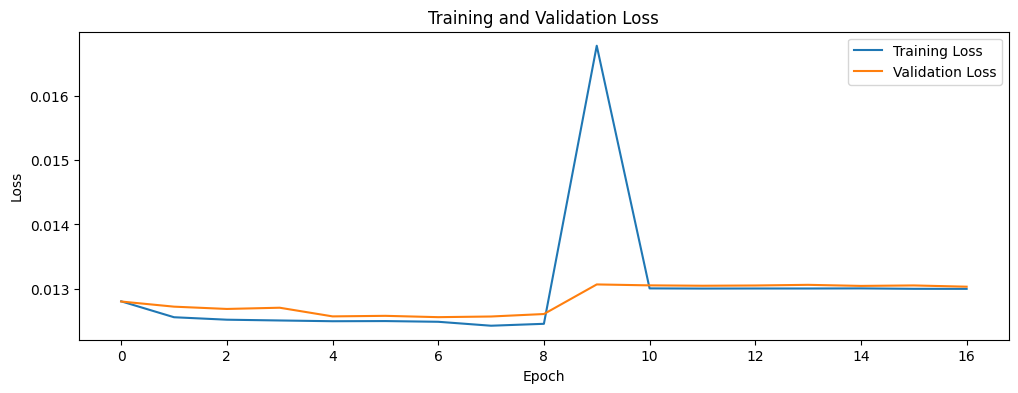

In [14]:
# Plot training history
def plot_training_history(history):
    """
    Plot training and validation loss
    """
    plt.figure(figsize=(12, 4))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.savefig('training_history.png')
    plt.show()

# Plot the training history
plot_training_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


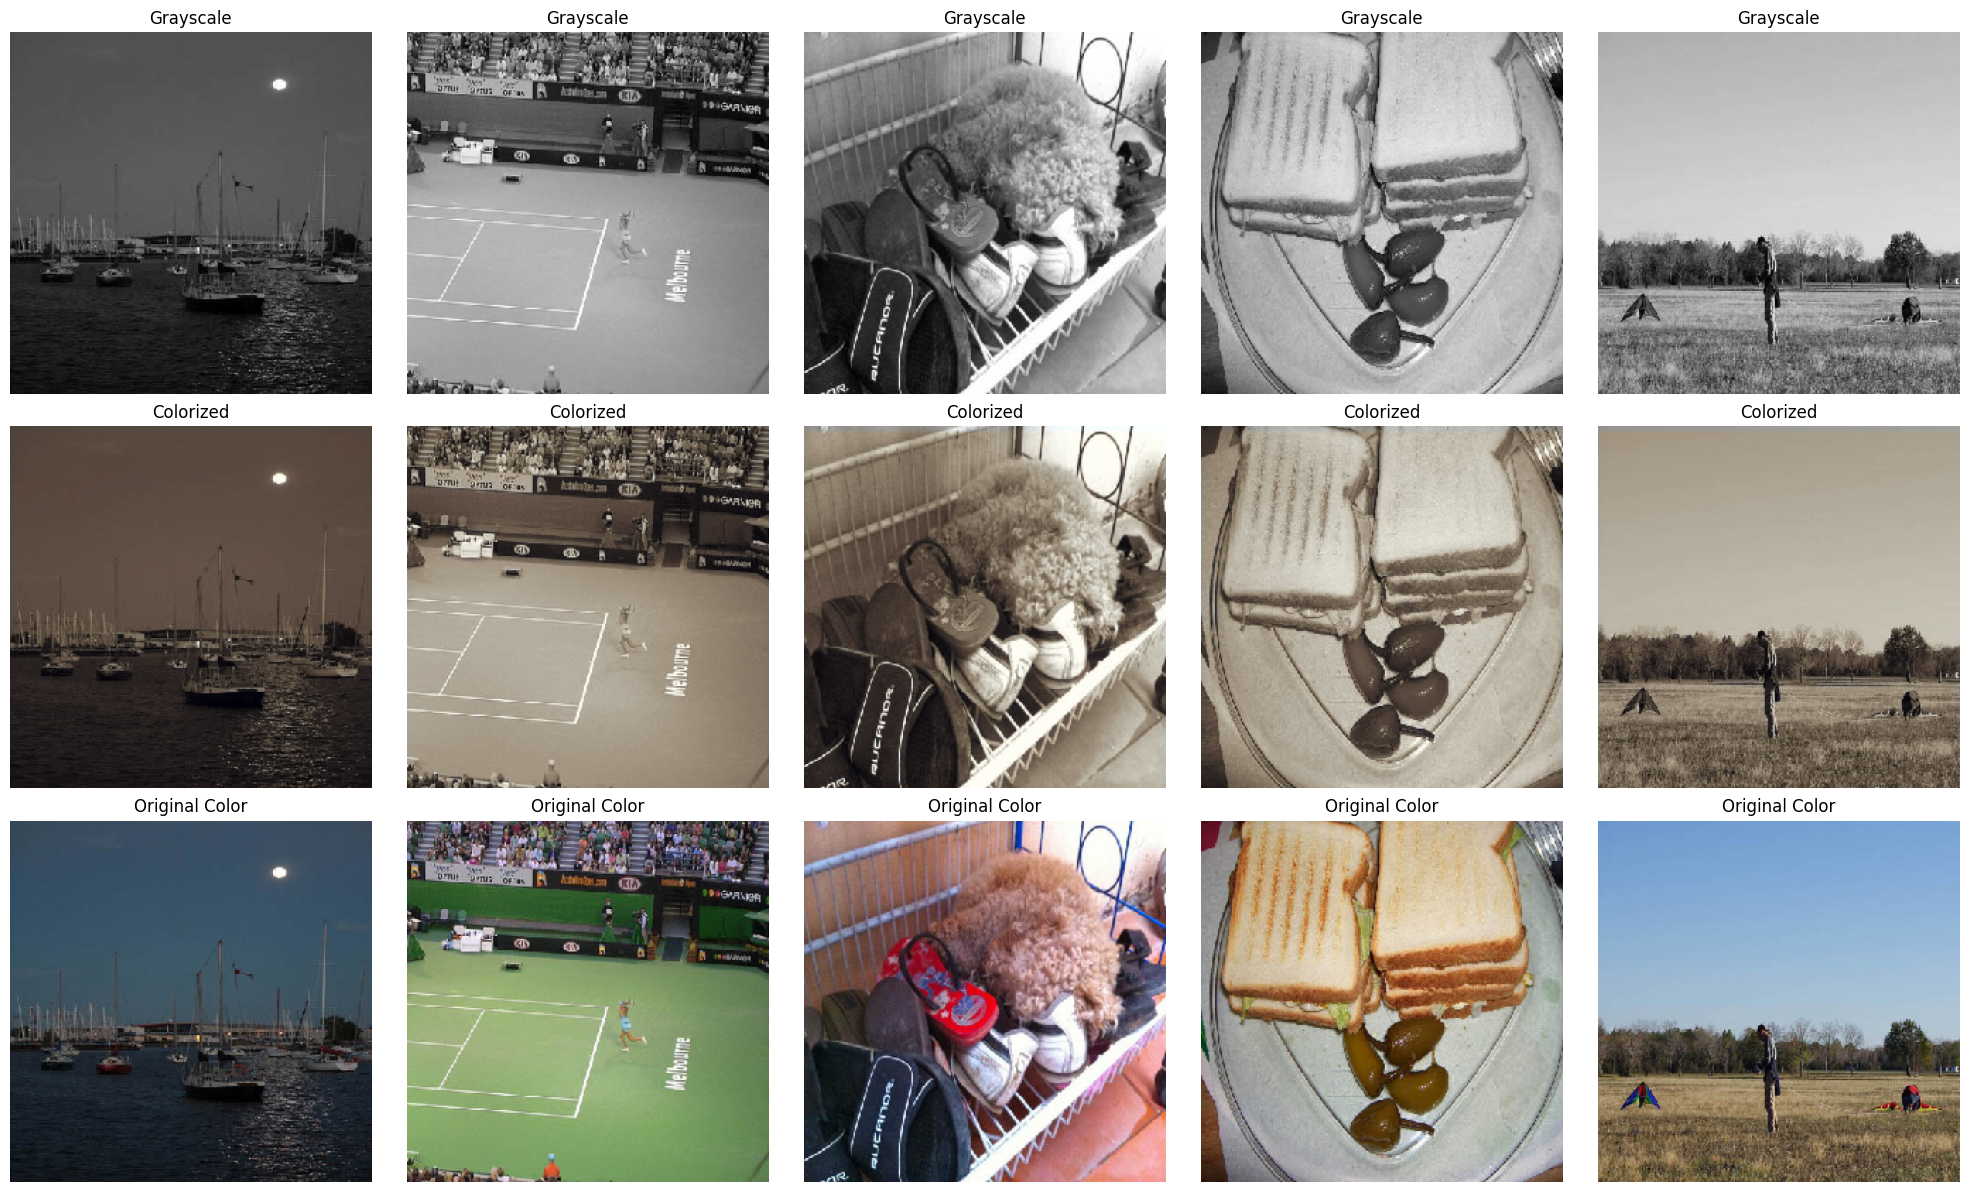

In [15]:
# Visualize original, grayscale, and colorized images
def visualize_colorization(model, l_test, ab_test, num_images=5):
    """
    Visualize original, grayscale, and colorized images
    """
    # Predict colors
    ab_pred = model.predict(l_test[:num_images])

    plt.figure(figsize=(20, 12))

    for i in range(num_images):
        # Original grayscale (L channel)
        plt.subplot(3, num_images, i + 1)
        plt.imshow(l_test[i].squeeze(), cmap='gray')
        plt.title('Grayscale')
        plt.axis('off')

        # Predicted color image
        plt.subplot(3, num_images, i + num_images + 1)

        # Combine L and predicted AB channels and convert back to RGB
        lab_pred = np.zeros((l_test[i].shape[0], l_test[i].shape[1], 3))
        lab_pred[:,:,0] = l_test[i].squeeze() * 100
        lab_pred[:,:,1:] = ab_pred[i] * 128

        # Convert LAB to RGB
        rgb_pred = color.lab2rgb(lab_pred)
        plt.imshow(rgb_pred)
        plt.title('Colorized')
        plt.axis('off')

        # Original color image
        plt.subplot(3, num_images, i + 2*num_images + 1)

        # Combine L and original AB channels
        lab_orig = np.zeros((l_test[i].shape[0], l_test[i].shape[1], 3))
        lab_orig[:,:,0] = l_test[i].squeeze() * 100
        lab_orig[:,:,1:] = ab_test[i] * 128

        # Convert LAB to RGB
        rgb_orig = color.lab2rgb(lab_orig)
        plt.imshow(rgb_orig)
        plt.title('Original Color')
        plt.axis('off')

    plt.tight_layout()
    plt.savefig('colorization_results.png')
    plt.show()

# Visualize results
visualize_colorization(model, l_test, ab_test, num_images=5)

In [19]:
class BaseColor(tf.keras.Model):
    def __init__(self):
        super(BaseColor, self).__init__()
        self.l_cent = 50.0
        self.l_norm = 100.0
        self.ab_norm = 110.0

    def normalize_l(self, in_l):
        return (in_l - self.l_cent) / self.l_norm

    def unnormalize_l(self, in_l):
        return in_l * self.l_norm + self.l_cent

    def normalize_ab(self, in_ab):
        return in_ab / self.ab_norm

    def unnormalize_ab(self, in_ab):
        return in_ab * self.ab_norm

class SIGGRAPHGenerator(BaseColor):
    def __init__(self, norm_layer=layers.BatchNormalization, classes=529):
        super(SIGGRAPHGenerator, self).__init__()

        def conv_block(filters, kernel_size=3, strides=1, dilation_rate=1, norm=True, activation=True):
            block = [layers.Conv2D(filters, kernel_size, strides=strides, padding='same', dilation_rate=dilation_rate)]
            if activation:
                block.append(layers.ReLU())
            if norm:
                block.append(norm_layer())
            return block

        def upsample_block(filters):
            return [layers.Conv2DTranspose(filters, kernel_size=4, strides=2, padding='same')]

        self.model1 = keras.Sequential(conv_block(64) + conv_block(64))
        self.model2 = keras.Sequential(conv_block(128) + conv_block(128))
        self.model3 = keras.Sequential(conv_block(256) + conv_block(256) + conv_block(256))
        self.model4 = keras.Sequential(conv_block(512) + conv_block(512) + conv_block(512))
        self.model5 = keras.Sequential(conv_block(512, dilation_rate=2) + conv_block(512, dilation_rate=2) + conv_block(512, dilation_rate=2))
        self.model6 = keras.Sequential(conv_block(512, dilation_rate=2) + conv_block(512, dilation_rate=2) + conv_block(512, dilation_rate=2))
        self.model7 = keras.Sequential(conv_block(512) + conv_block(512) + conv_block(512))

        self.model8up = keras.Sequential(upsample_block(256))
        self.model8 = keras.Sequential(conv_block(256) + conv_block(256) + conv_block(256))
        self.model9up = keras.Sequential(upsample_block(128))
        self.model9 = keras.Sequential(conv_block(128) + conv_block(128))
        self.model10up = keras.Sequential(upsample_block(128))
        self.model10 = keras.Sequential([layers.ReLU()] + conv_block(128, activation=False) + [layers.LeakyReLU(alpha=0.2)])

        self.model3short8 = keras.Sequential([layers.Conv2D(256, 3, padding='same')])
        self.model2short9 = keras.Sequential([layers.Conv2D(128, 3, padding='same')])
        self.model1short10 = keras.Sequential([layers.Conv2D(128, 3, padding='same')])

        self.model_class = keras.Sequential([layers.Conv2D(classes, 1, padding='same')])
        self.model_out = keras.Sequential([layers.Conv2D(2, 1, padding='same'), layers.Activation('tanh')])

        self.upsample4 = keras.Sequential([layers.UpSampling2D(size=4, interpolation='bilinear')])
        self.softmax = keras.Sequential([layers.Softmax(axis=-1)])

    def call(self, input_A, input_B=None, mask_B=None):
        if input_B is None:
            input_B = tf.zeros_like(input_A)
        if mask_B is None:
            mask_B = tf.zeros_like(input_A)

        input_combined = tf.concat([self.normalize_l(input_A), self.normalize_ab(input_B), mask_B], axis=-1)
        conv1_2 = self.model1(input_combined)
        conv2_2 = self.model2(layers.AveragePooling2D()(conv1_2))
        conv3_3 = self.model3(layers.AveragePooling2D()(conv2_2))
        conv4_3 = self.model4(layers.AveragePooling2D()(conv3_3))
        conv5_3 = self.model5(conv4_3)
        conv6_3 = self.model6(conv5_3)
        conv7_3 = self.model7(conv6_3)

        conv8_up = self.model8up(conv7_3) + self.model3short8(conv3_3)
        conv8_3 = self.model8(conv8_up)
        conv9_up = self.model9up(conv8_3) + self.model2short9(conv2_2)
        conv9_3 = self.model9(conv9_up)
        conv10_up = self.model10up(conv9_3) + self.model1short10(conv1_2)
        conv10_2 = self.model10(conv10_up)
        out_reg = self.model_out(conv10_2)

        return self.unnormalize_ab(out_reg)